# 11 - Linear first-order equations; existence and uniqueness

**MATH 331 - Differential Equations.** Lecture plan: Session 5 (Unit 2: linear equations, integrating factor, existence and uniqueness; the non-unique case).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 1.4** (integrating factor; Example 1.4.1; formula
  (1.4.5); Exercises 1.4.3, 1.4.7, 1.4.11, 1.4.13) and **Section 1.2** (Theorem 1.2.1, Picard;
  Examples 1.2.1-1.2.3; Exercise 1.2.5).
* Exercise numbers are those of the exercise lists at the end of each chapter of the
  LibreTexts edition, except Exercise 1.4.3, which is in the text of Section 1.4.
* Prerequisites: videos R01 (product rule), R02 and R03 (integration); notebooks 09 and 10.

**What you will learn**
1. The second **method** of the course: the integrating factor, for linear equations.
2. The shape of every solution of a linear equation: one particular solution plus a part that
   contains the constant.
3. The first **theorem**: when a solution exists, when it is the only one, and how far it goes.
4. What happens when the theorem does not apply, and why the computer does not warn you.

## 1. Theory in brief

**Linear equation, standard form:** $\;y' + p(x)\,y = f(x)$.

**The integrating factor method.**

1. Write the equation in standard form (the coefficient of $y'$ must be 1).
2. Compute the **integrating factor** $r(x) = e^{\int p(x)\,dx}$ (any antiderivative, no constant).
3. Multiply the equation by $r$. Since $r' = r\,p$, the left side is the derivative of a product:
   $\;r\,y' + r\,p\,y = (r\,y)'$. So $(r\,y)' = r\,f$.
4. Integrate, $r\,y = \int r f\,dx + C$, and divide by $r$.

*Do not memorise the final formula: remember the process and repeat it* (Lebl, Section 1.4).

**Picard's theorem** (Lebl, Theorem 1.2.1). If $f(x, y)$ is continuous and $\dfrac{\partial f}{\partial y}$
exists and is continuous near $(x_0, y_0)$, then the problem $y' = f(x, y)$, $y(x_0) = y_0$ has a
solution, at least on some small interval around $x_0$, and only one.

**For linear equations more is true.** If $p$ and $f$ are continuous on an interval $(a, b)$
containing $x_0$, the solution of $y' + p\,y = f$, $y(x_0) = y_0$ exists and is unique on the
**whole** interval $(a, b)$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: slope_field, linear_first_order, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The integrating factor, step by step

*Lebl, Example 1.4.1.* Solve $\;y' + 2xy = e^{x - x^2}$, $\;y(0) = -1$.

By hand:

1. It is in standard form: $p(x) = 2x$, $f(x) = e^{x - x^2}$.
2. $r(x) = e^{\int 2x\,dx} = e^{x^2}$.
3. $\big(e^{x^2}y\big)' = e^{x^2}e^{x - x^2} = e^{x}$.
4. $e^{x^2}y = e^{x} + C$, so $y = e^{x - x^2} + C\,e^{-x^2}$.

Initial condition: $-1 = y(0) = 1 + C$, so $C = -2$ and $\;y = e^{x - x^2} - 2e^{-x^2}$.

The same four steps with SymPy:

In [2]:
x, t, C = sp.symbols("x t C")
unknown = sp.Function("y")(x)                  # an unknown function y(x), for the check of step 3


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


p = 2 * x                                      # step 1
f = sp.exp(x - x ** 2)

r = sp.exp(sp.integrate(p, x))                 # step 2
print("integrating factor r =", r)

# step 3: r y' + r p y is the derivative of r y
assert residual(sp.diff(r * unknown, x), r * sp.diff(unknown, x) + r * p * unknown) == 0
right_side = sp.simplify(r * f)
print("(r y)' =", right_side)

general = (sp.integrate(right_side, x) + C) / r        # step 4
print("general solution: y =", sp.expand(general))

constant = sp.solve(general.subs(x, 0) - (-1), C)[0]   # y(0) = -1
solution = sp.expand(general.subs(C, constant))
print("C =", constant, "   y =", solution)

assert constant == -2
assert residual(solution, sp.exp(x - x ** 2) - 2 * sp.exp(-x ** 2)) == 0
assert residual(sp.diff(solution, x) + p * solution, f) == 0

integrating factor r = exp(x**2)


(r y)' = exp(x)
general solution: y = C*exp(-x**2) + exp(x)*exp(-x**2)
C = -2    y = exp(x)*exp(-x**2) - 2*exp(-x**2)


The picture: the slope field of $y' = e^{x - x^2} - 2xy$, some solutions (different $C$) and the
one that passes through $(0, -1)$.

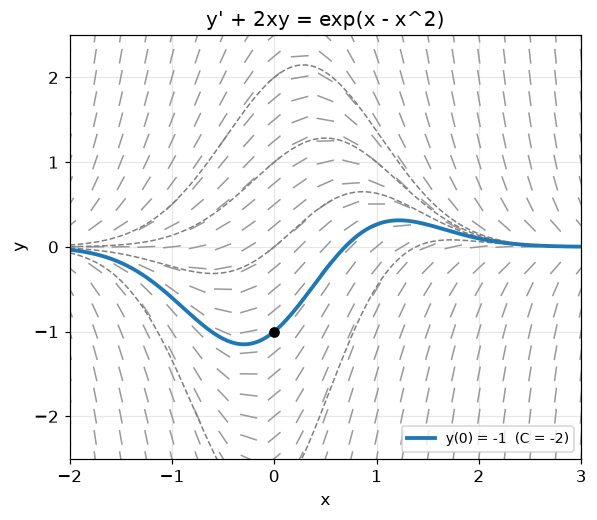

In [3]:
def slope_example(x, y):
    return np.exp(x - x ** 2) - 2 * x * y


def family_example(x, c):
    return np.exp(x - x ** 2) + c * np.exp(-x ** 2)


X_RANGE = (-2.0, 3.0)
Y_RANGE = (-2.5, 2.5)
FIGURE_SIZE = (6.0, 5.0)
WIDE_FIGURE = (7.0, 3.6)
N_POINTS = 400
OTHER_CONSTANTS = (-4.0, -1.0, 0.0, 1.0)
START = (0.0, -1.0)

x_values = np.linspace(*X_RANGE, N_POINTS)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, slope_example, X_RANGE, Y_RANGE)
for c in OTHER_CONSTANTS:
    ax.plot(x_values, family_example(x_values, c), "--", color="gray", linewidth=1)
ax.plot(x_values, family_example(x_values, float(constant)), "-", linewidth=2.5, label="y(0) = -1  (C = -2)")
ax.plot(*START, "o", color="black")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' + 2xy = exp(x - x^2)")
ax.legend(loc="lower right")
plt.show()

*The plot shows* the solution through $(0, -1)$ (thick line): it starts near 0 on the left, dips
to about $-1.15$ near $x = -0.3$, passes through $(0, -1)$ already rising, goes above the axis and returns to 0 on the right. The thin dashed
curves are other members of the family. All of them come together and go to 0 as $x$ grows.

## 3. The shape of the answer

In notebook 09 we found, from the isoclines, that the line $y = x - 1$ is a solution of
$y' = x - y$, and we saw the other solutions approach it. Now we can prove it. In standard form:

$$ y' + y = x, \qquad r = e^{x}, \qquad (e^{x}y)' = x\,e^{x}, \qquad e^{x}y = (x - 1)e^{x} + C $$

(integration by parts, video R03), so

$$ y = \underbrace{x - 1}_{\text{one particular solution}} \;+\; \underbrace{C\,e^{-x}}_{\text{solutions of } y' + y = 0} . $$

**This is the shape of the solutions of every linear equation**: one solution of the full
equation, plus all the solutions of the equation with zero on the right (the *homogeneous*
equation). Here the second part goes to 0: it is a **transient**. After a while every solution
looks like $x - 1$, whatever the initial condition.

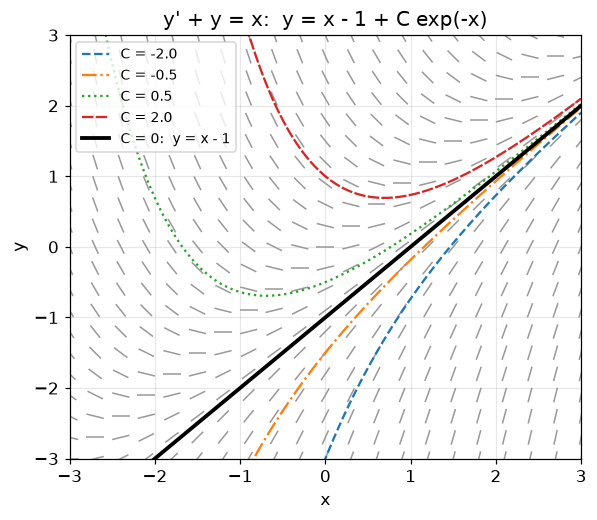

In [4]:
def slope_x_minus_y(x, y):
    return x - y


SQUARE_RANGE = (-3.0, 3.0)
TRANSIENT_CONSTANTS = (-2.0, -0.5, 0.5, 2.0)
LINE_STYLES = ("--", "-.", ":", (0, (5, 1)))

family = x - 1 + C * sp.exp(-x)
assert residual(sp.diff(family, x) + family, x) == 0

x_square = np.linspace(*SQUARE_RANGE, N_POINTS)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, slope_x_minus_y, SQUARE_RANGE, SQUARE_RANGE)
for c, style in zip(TRANSIENT_CONSTANTS, LINE_STYLES):
    ax.plot(x_square, x_square - 1 + c * np.exp(-x_square), linestyle=style, linewidth=1.5, label=f"C = {c}")
ax.plot(x_square, x_square - 1, "-", color="black", linewidth=2.5, label="C = 0:  y = x - 1")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' + y = x:  y = x - 1 + C exp(-x)")
ax.legend(loc="upper left")
plt.show()

*The plot shows* the straight line $y = x - 1$ (thick, black) and four other solutions. On the
left they are far from the line, above it for $C > 0$ and below it for $C < 0$; moving to the
right they all bend towards the line and become indistinguishable from it.

## 4. When the integral has no formula

*Lebl, Exercise 1.4.3 (in the text of Section 1.4).* $\;y' + y = e^{x^2 - x}$, $\;y(0) = 10$.

The method works as before: $r = e^{x}$ and $(e^{x}y)' = e^{x}e^{x^2 - x} = e^{x^2}$. But
$\int e^{x^2}dx$ **cannot be written with the functions you know**. This is not a failure of the
method: the solution is written with a *definite* integral (Lebl, formula (1.4.5)),

$$ y(x) = e^{-x}\Big(10 + \int_0^x e^{t^2}\,dt\Big), $$

and a definite integral is something a computer can evaluate. `ol.linear_first_order` does
exactly this, for any $p$ and $f$. We compare it with `solve_ivp`, which knows nothing of
integrating factors and just follows the slopes.

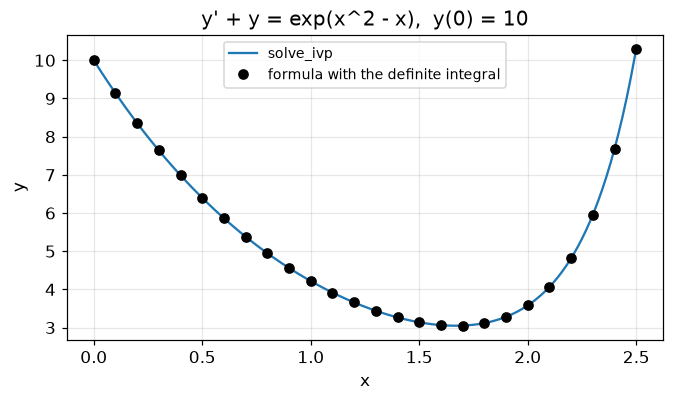

y(1) = 4.2169 (definite integral), 4.2169 (solve_ivp)


In [5]:
def p_one(s):
    return 1.0


def f_gauss(s):
    return np.exp(s * s - s)


X_END = 2.5
N_DOTS = 26
X_CHECK = 1.0
Y_START = 10.0
TOLERANCE = 1e-10

x_dots = np.linspace(0.0, X_END, N_DOTS)
y_formula = ol.linear_first_order(p_one, f_gauss, 0.0, Y_START, x_dots)
numerical = solve_ivp(lambda s, y: f_gauss(s) - p_one(s) * y, (0.0, X_END), [Y_START],
                      dense_output=True, rtol=TOLERANCE, atol=TOLERANCE)
x_fine = np.linspace(0.0, X_END, N_POINTS)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(x_fine, numerical.sol(x_fine)[0], "-", label="solve_ivp")
ax.plot(x_dots, y_formula, "o", color="black", label="formula with the definite integral")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' + y = exp(x^2 - x),  y(0) = 10")
ax.legend()
plt.show()

y_check = ol.linear_first_order(p_one, f_gauss, 0.0, Y_START, X_CHECK)
print(f"y({X_CHECK:.0f}) = {y_check:.4f} (definite integral), {numerical.sol(X_CHECK)[0]:.4f} (solve_ivp)")
assert np.isclose(y_check, numerical.sol(X_CHECK)[0])
assert np.allclose(y_formula, numerical.sol(x_dots)[0])

*The plot shows* the solution falling from 10 to a minimum of about 3.0 near $x = 1.7$ and then
rising faster and faster. The dots (formula with the definite integral) lie on the curve
(numerical solution).

## 5. Existence and uniqueness

Notebooks 09 and 10 left three strange facts: a problem with **two** solutions, solutions that
**stop** after a short while, and an empty tank that does not remember when it emptied. Picard's
theorem (Section 1) says when none of this can happen. It has **two hypotheses**, to be checked
at the initial point $(x_0, y_0)$:

1. $f(x, y)$ is continuous near the point;
2. $\dfrac{\partial f}{\partial y}$ exists and is continuous near the point.

Four problems you know:

| Problem | Hypothesis 1 | Hypothesis 2 | What happens |
|---|---|---|---|
| $y' = xy$, any point | yes | yes: $\partial f/\partial y = x$ | one solution through each point (notebook 09) |
| $y' = \dfrac1x$, $y(0) = 0$ | **no**: $f$ is not defined at $x = 0$ | - | **no solution**: $y = \ln\lvert x\rvert + C$ does not exist at 0 (Lebl, Example 1.2.1) |
| $y' = 2\sqrt{\lvert y\rvert}$, $y(0) = 0$ | yes | **no**: $\partial f/\partial y = \pm 1/\sqrt{\lvert y\rvert}$ is unbounded near $y = 0$ | **more than one solution**: $y = 0$, and $y = x^2$ for $x \ge 0$ (Lebl, Example 1.2.2) |
| $y' = y^2$, $y(0) = A > 0$ | yes | yes: $\partial f/\partial y = 2y$ | one solution, but only for $x < 1/A$ (Lebl, Example 1.2.3) |

The last line is not a contradiction: the theorem promises a solution on **some small interval**
around $x_0$, and says nothing about how long it lasts. SymPy computes the derivatives of the
table (for $y > 0$; the second problem has no $\partial f/\partial y$ to compute, because $f$ itself
fails at $x = 0$):

In [6]:
y = sp.symbols("y", positive=True)             # y > 0: enough to see what happens near y = 0

RIGHT_SIDES = {"x y": x * y, "2 sqrt(y)": 2 * sp.sqrt(y), "y^2": y ** 2}

for name, right in RIGHT_SIDES.items():
    print(f"f = {name:10s}  df/dy = {sp.simplify(sp.diff(right, y))}")

f = x y         df/dy = x
f = 2 sqrt(y)   df/dy = 1/sqrt(y)
f = y^2         df/dy = 2*y


**Linear equations are better.** For $y' + p(x)\,y = f(x)$ the solution exists and is unique on
the whole interval around $x_0$ where $p$ and $f$ are continuous. So the interval can be read
from the equation, **before solving it**.

*Example.* $\;x\,y' + y = 2x$, $\;y(1) = 2$. Standard form: $y' + \dfrac1x\,y = 2$. Here
$p = 1/x$ is continuous for $x > 0$ and for $x < 0$; the initial point $x_0 = 1$ is in the first
interval: the theorem promises a solution for **all** $x > 0$. Solving: $r = x$,
$(xy)' = 2x$, $y = x + \dfrac{C}{x}$, and $y(1) = 2$ gives $C = 1$.

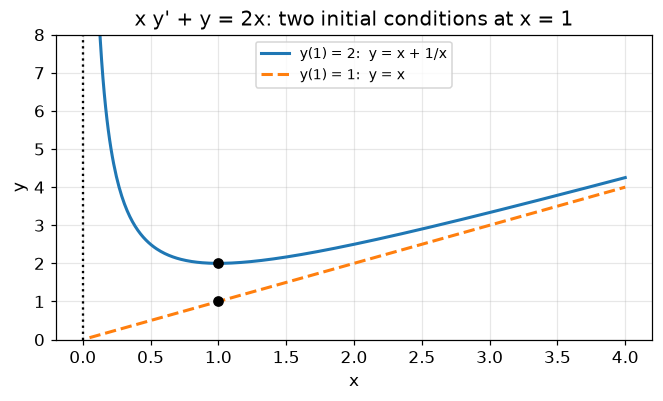

In [7]:
candidate = x + C / x
assert residual(x * sp.diff(candidate, x) + candidate, 2 * x) == 0

POSITIVE_RANGE = (0.05, 4.0)
Y_LIMITS = (0.0, 8.0)
x_positive = np.linspace(*POSITIVE_RANGE, N_POINTS)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(x_positive, x_positive + 1 / x_positive, "-", linewidth=2, label="y(1) = 2:  y = x + 1/x")
ax.plot(x_positive, x_positive, "--", linewidth=2, label="y(1) = 1:  y = x")
ax.axvline(0.0, linestyle=":", color="black")
ax.plot([1.0, 1.0], [2.0, 1.0], "o", color="black")
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("x y' + y = 2x: two initial conditions at x = 1")
ax.legend(loc="upper center")
plt.show()

assert candidate.subs({C: 1, x: 1}) == 2 and candidate.subs({C: 0, x: 1}) == 1

*The plot shows* two solutions starting at $x = 1$ (black dots). The solid one, $y = x + 1/x$,
goes to infinity as $x$ approaches 0 (dotted vertical line): it lives exactly on $x > 0$, the
interval promised by the theorem. The dashed one, $y = x$, is a straight line.

With $y(1) = 1$ the constant is $C = 0$ and the solution $y = x$ makes sense for every $x$, also
across $x = 0$. The theorem is a **guarantee**, not a limit: the solution exists *at least* on
the promised interval.

## 6. The non-unique case: $y' = y^{1/3}$

$$ y' = y^{1/3}, \qquad y(0) = 0 . $$

* $y = 0$ is a solution.
* Separating variables (notebook 10): $y^{-1/3}dy = dx$, $\tfrac32 y^{2/3} = x + C$; with
  $y(0) = 0$, $C = 0$ and $\;y = \big(\tfrac{2x}{3}\big)^{3/2}$ for $x \ge 0$. **Another** solution.
* $y = -\big(\tfrac{2x}{3}\big)^{3/2}$ is a third one.
* And more: stay at 0 until any $x = c \ge 0$, then take off:
  $\;y = \big(\tfrac{2(x - c)}{3}\big)^{3/2}$ for $x \ge c$. One solution for each $c$:
  **infinitely many**.

Which hypothesis fails? $f = y^{1/3}$ is continuous, but
$\dfrac{\partial f}{\partial y} = \dfrac{1}{3\,y^{2/3}}$ is unbounded near $y = 0$: hypothesis 2.

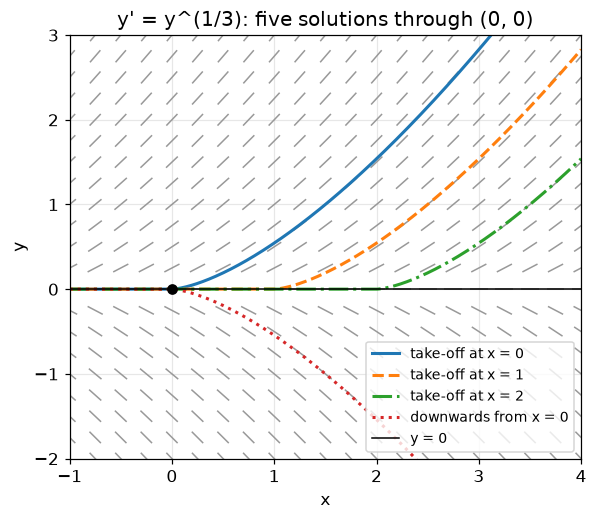

In [8]:
def slope_cube_root(x, y):
    return np.cbrt(y)                          # the cube root, also for negative y


def take_off(x, c):
    # 0 up to x = c, then ((2/3)(x - c))^(3/2)
    return (2 * np.maximum(x - c, 0.0) / 3) ** 1.5


ROOT_X_RANGE = (-1.0, 4.0)
ROOT_Y_RANGE = (-2.0, 3.0)
TAKE_OFF_POINTS = (0.0, 1.0, 2.0)
TAKE_OFF_STYLES = ("-", "--", "-.")

# the upper branch is a solution (x_pos > 0), and so is its mirror image
x_pos = sp.symbols("x_pos", positive=True)
branch = (2 * x_pos / 3) ** sp.Rational(3, 2)
assert residual(sp.diff(branch, x_pos), branch ** sp.Rational(1, 3)) == 0

x_root = np.linspace(*ROOT_X_RANGE, N_POINTS)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, slope_cube_root, ROOT_X_RANGE, ROOT_Y_RANGE)
for c, style in zip(TAKE_OFF_POINTS, TAKE_OFF_STYLES):
    ax.plot(x_root, take_off(x_root, c), linestyle=style, linewidth=2, label=f"take-off at x = {c:.0f}")
ax.plot(x_root, -take_off(x_root, TAKE_OFF_POINTS[0]), ":", linewidth=2, label="downwards from x = 0")
ax.plot(x_root, np.zeros_like(x_root), "-", color="black", linewidth=1, label="y = 0")
ax.plot(0.0, 0.0, "o", color="black")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = y^(1/3): five solutions through (0, 0)")
ax.legend(loc="lower right")
plt.show()

*The plot shows* five curves through the point $(0, 0)$ on the slope field of $y' = y^{1/3}$:
the $x$ axis; a curve leaving the axis upwards at $x = 0$, one at $x = 1$ and one at $x = 2$;
and one leaving downwards at $x = 0$. All of them follow the grey segments.

The reason, in one picture: the slope of $f$ in the $y$ direction near $y = 0$.

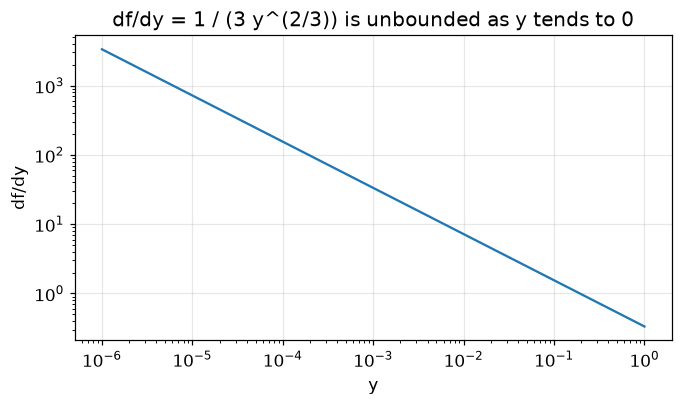

y = 1e+00   df/dy = 0.3
y = 1e-03   df/dy = 33.3
y = 1e-06   df/dy = 3333.3


In [9]:
Y_EXPONENTS = (-6, 0)                          # y from 10^-6 to 1
y_small = np.logspace(*Y_EXPONENTS, 100)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.loglog(y_small, 1 / (3 * y_small ** (2 / 3)), "-")
ax.set_xlabel("y")
ax.set_ylabel("df/dy")
ax.set_title("df/dy = 1 / (3 y^(2/3)) is unbounded as y tends to 0")
plt.show()

for value in (1.0, 1e-3, 1e-6):
    print(f"y = {value:.0e}   df/dy = {1 / (3 * value ** (2 / 3)):.1f}")

*The plot shows*, on logarithmic axes, $\partial f/\partial y$ against $y$: a straight line going
up to the left, from $0.33$ at $y = 1$ to $3333$ at $y = 10^{-6}$. It has no bound as $y \to 0$.

**What does the computer do?** Ask `solve_ivp` to solve the problem, first from $y(0) = 0$ and
then from $y(0) = 10^{-9}$, a number smaller than any measurement error.

In [10]:
X_FINAL = 3.0
TINY = 1e-9
SOLVER_TOLERANCE = 1e-10

from_zero = solve_ivp(slope_cube_root, (0.0, X_FINAL), [0.0], rtol=SOLVER_TOLERANCE, atol=SOLVER_TOLERANCE**1.5)
from_tiny = solve_ivp(slope_cube_root, (0.0, X_FINAL), [TINY], rtol=SOLVER_TOLERANCE, atol=SOLVER_TOLERANCE**1.5)
upper = take_off(X_FINAL, 0.0)

print(f"from y(0) = 0     : y({X_FINAL:.0f}) = {from_zero.y[0, -1]:.4f}")
print(f"from y(0) = {TINY:.0e} : y({X_FINAL:.0f}) = {from_tiny.y[0, -1]:.4f}")
print(f"upper branch      : y({X_FINAL:.0f}) = {upper:.4f}  (= 2 sqrt 2)")

assert from_zero.y[0, -1] == 0.0
assert np.isclose(from_tiny.y[0, -1], upper, rtol=1e-4)
assert np.isclose(upper, 2 * np.sqrt(2))

from y(0) = 0     : y(3) = 0.0000
from y(0) = 1e-09 : y(3) = 2.8284
upper branch      : y(3) = 2.8284  (= 2 sqrt 2)


From 0 the computer returns $y = 0$; from $10^{-9}$ it returns the upper branch, $2.83$ at
$x = 3$. Each answer is a correct solution of the problem it was given (the second one approximates the
upper branch), and **neither comes with a warning**: nothing says that the first problem has
other solutions.

> A numerical answer does not tell you that the solution is not unique. The theorem does: check
> its hypotheses **before** trusting a computation.

This is also the tank of notebook 10 seen backwards ($h' = -c\sqrt h$ reaches $h = 0$ in finite
time), and the example $y' = 2\sqrt{|y|}$ of notebook 09.

**Slider.** Before moving it: how many solutions of $y' = y^{1/3}$ pass through $(0, 0)$? And
through $(0, 1)$?

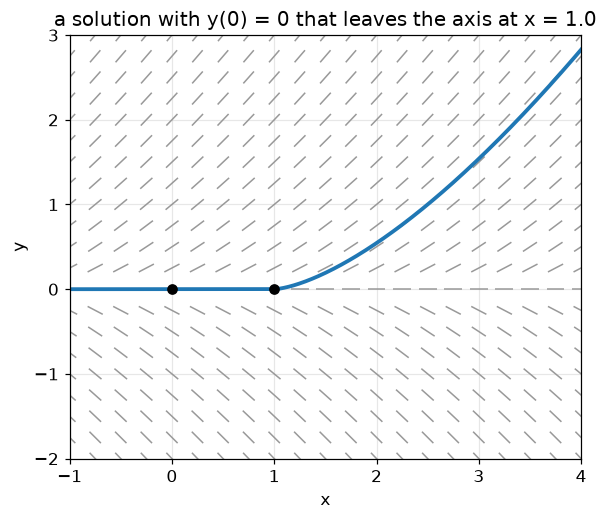

In [11]:
def plot_take_off(c=TAKE_OFF_POINTS[1]):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, slope_cube_root, ROOT_X_RANGE, ROOT_Y_RANGE)
    ax.plot(x_root, take_off(x_root, c), "-", linewidth=2.5)
    ax.plot([0.0, c], [0.0, 0.0], "o", color="black")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"a solution with y(0) = 0 that leaves the axis at x = {c:.1f}")
    plt.show()


plot_take_off()

In [12]:
TAKE_OFF_RANGE = (0.0, 3.0, 0.1)        # minimum, maximum, step

interact(plot_take_off,
         c=FloatSlider(value=TAKE_OFF_POINTS[1], min=TAKE_OFF_RANGE[0], max=TAKE_OFF_RANGE[1],
                       step=TAKE_OFF_RANGE[2], description="take-off", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='take-off', max=3.0), Output...

(Through $(0, 0)$: infinitely many. Through $(0, 1)$: exactly one, because near $y = 1$ both
hypotheses hold.)

## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

For each problem: does Picard's theorem **guarantee** one and only one solution near the initial
point? Check the two hypotheses by hand, then type `True` or `False` for each, in a list.

1. $y' = y\sqrt{|x|}$, $\;y(0) = 0$ (*Lebl, Exercise 1.2.5*)
2. $y' = y^{1/3}$, $\;y(1) = 1$
3. $y' = y^{1/3}$, $\;y(1) = 0$
4. $y' = \dfrac{x}{y}$, $\;y(0) = 0$

In [13]:
my_guarantees = None            # for example [True, True, True, True]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1", my_guarantees, [True, True, False, False]);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 1.4.11.* Solve $y' + 2\sin(2x)\,y = 2\sin(2x)$, $y(\pi/2) = 3$. Type the
solution as an expression in `x` (use `sp.exp`, `sp.cos`).

In [14]:
my_y = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

X_INTERVAL = (0.0, 3.0)
expected_a = 2 * sp.exp(sp.cos(2 * x) + 1) + 1          # the answer printed in Lebl
assert residual(sp.diff(expected_a, x) + 2 * sp.sin(2 * x) * expected_a, 2 * sp.sin(2 * x)) == 0
ol.check_formula("Exercise 2a", my_y, expected_a, x, X_INTERVAL);

Exercise 2a: no answer yet (replace None with your formula)


**(b)** *Lebl, Exercise 1.4.13.* Bacteria on a plate, with a toxic substance slowly added:
$P' = (2 - 0.1\,t)\,P$, $P(0) = 1000$. Find $P(5)$. The equation is linear **and** separable:
solve it both ways. Type the number (three significant digits are enough, for example `6.02e6`).

In [15]:
my_P5 = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

PERCENT = 1e-2                  # an answer within one per cent is accepted
expected_P5 = ol.linear_first_order(lambda s: -(2 - 0.1 * s), lambda s: 0.0, 0.0, 1000.0, 5.0)
assert np.isclose(expected_P5, 1000 * np.exp(8.75))     # the answer printed in Lebl

if my_P5 is None:
    ol.check("Exercise 2b", None, 1.0)
else:
    ol.check("Exercise 2b", my_P5 / expected_P5, 1.0, tol=PERCENT);

Exercise 2b: no answer yet (replace None with your value)


**(c)** Without solving: on which interval does the theorem for linear equations promise a
solution of

$$ y' + \frac{y}{x - 3} = \frac{1}{x + 1}, \qquad y(0) = 1 \;? $$

Type its two ends in a list, the left one first.

In [16]:
my_interval = None              # for example [0, 1]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 2c", my_interval, [-1, 3]);

Exercise 2c: no answer yet (replace None with your value)

### Exercise 3 - Fill in

Solve by hand $y' + 2y = 4$, $y(0) = 0$ with the integrating factor. Then complete `y_exact`
with your solution (use `np.exp`). The next cell compares it with `solve_ivp` and plots both.

In [17]:
def y_exact(x):
    return None                 # replace None with the formula

In [18]:
if y_exact(0.0) is None:
    print("Exercise 3: complete y_exact first")
else:
    X_LAST = 3.0
    check_solution = solve_ivp(lambda s, y: 4 - 2 * y, (0.0, X_LAST), [0.0], dense_output=True,
                               rtol=TOLERANCE, atol=TOLERANCE)
    x_test = np.linspace(0.0, X_LAST, N_DOTS)
    assert np.isclose(y_exact(0.0), 0.0), "the initial condition is y(0) = 0"
    assert np.allclose(y_exact(x_test), check_solution.sol(x_test)[0], atol=1e-6), "not the solution: check r and C"
    print("Exercise 3: correct")
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(x_fine * X_LAST / X_END, check_solution.sol(x_fine * X_LAST / X_END)[0], "-", label="solve_ivp")
    ax.plot(x_test, y_exact(x_test), "o", color="black", label="your formula")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    plt.show()

Exercise 3: complete y_exact first


### Exercise 4 - Explore

*Lebl, Exercise 1.4.7.* A room exchanges heat with the outside, where the temperature oscillates
between day and night: Newton's law of cooling with a moving target,

$$ x' = -k\,\big(x - A_0\cos(\omega t)\big) . $$

The function below draws the numerical solutions for several initial temperatures (time in
hours, period 24 hours). Run it, then change `k`:

* Do the initial conditions matter in the long term? Why? (Look at Section 3.)
* With a small `k` (thick walls), what happens to the size of the oscillation inside, and to its
  delay with respect to the outside?
* Find the general solution by hand (integrating factor, then integration by parts twice) and
  compare with the picture.

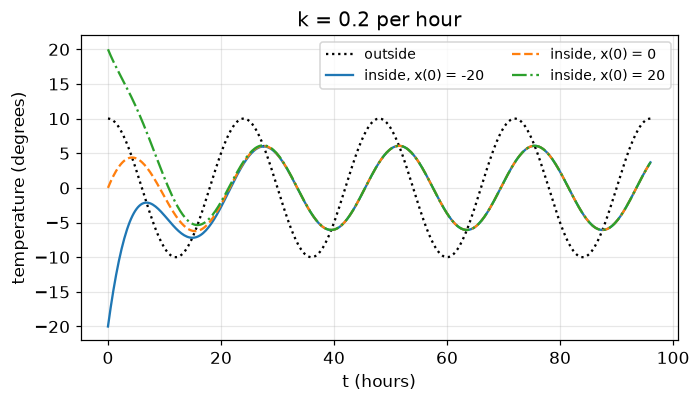

In [19]:
HOURS_PER_DAY = 24.0
OMEGA = 2 * np.pi / HOURS_PER_DAY       # one oscillation a day
AMPLITUDE = 10.0                        # the outside goes from -10 to +10 degrees
DAYS = 4
INITIAL_TEMPERATURES = (-20.0, 0.0, 20.0)
ROOM_STYLES = ("-", "--", "-.")


def plot_room(k=0.2):
    hours = np.linspace(0.0, DAYS * HOURS_PER_DAY, N_POINTS)
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(hours, AMPLITUDE * np.cos(OMEGA * hours), ":", color="black", label="outside")
    for start, style in zip(INITIAL_TEMPERATURES, ROOM_STYLES):
        room = solve_ivp(lambda s, temp: -k * (temp - AMPLITUDE * np.cos(OMEGA * s)),
                         (0.0, hours[-1]), [start], dense_output=True, rtol=1e-8, atol=1e-8)
        ax.plot(hours, room.sol(hours)[0], linestyle=style, label=f"inside, x(0) = {start:.0f}")
    ax.set_xlabel("t (hours)")
    ax.set_ylabel("temperature (degrees)")
    ax.set_title(f"k = {k} per hour")
    ax.legend(loc="upper right", ncol=2)
    plt.show()


plot_room()

# your code here: for example plot_room(0.05)

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `[True, True, False, False]`. (1) $f$ and $\partial f/\partial y = \sqrt{|x|}$ are continuous:
   the only solution is $y = 0$. (2) Near $y = 1$ both hypotheses hold. (3) At $y = 0$ the
   derivative $\partial f/\partial y$ is unbounded: no guarantee (and in fact there are infinitely
   many solutions). (4) $f = x/y$ is not continuous at $y = 0$: no guarantee.
2. (a) $y = 2e^{\cos(2x) + 1} + 1$. (b) $P(5) = 1000\,e^{8.75} \approx 6.31\times 10^{6}$.
   (c) $-1 < x < 3$: `[-1, 3]`.
3. `return 2 * (1 - np.exp(-2 * x))`
4. No: the solution is
   $x = \dfrac{A_0 k\,(k\cos\omega t + \omega\sin\omega t)}{k^2 + \omega^2} + C\,e^{-kt}$, and the
   part with the initial condition, $Ce^{-kt}$, is a transient. With a small $k$ the oscillation
   inside is smaller (amplitude $A_0 k/\sqrt{k^2 + \omega^2}$) and later (up to a quarter of a
   day).

</details>

**Where to go next:** notebook 02 (radioactive decay chains) uses the integrating factor on a
real problem; notebook 12 (exact equations and substitutions, Session 6) comes next.